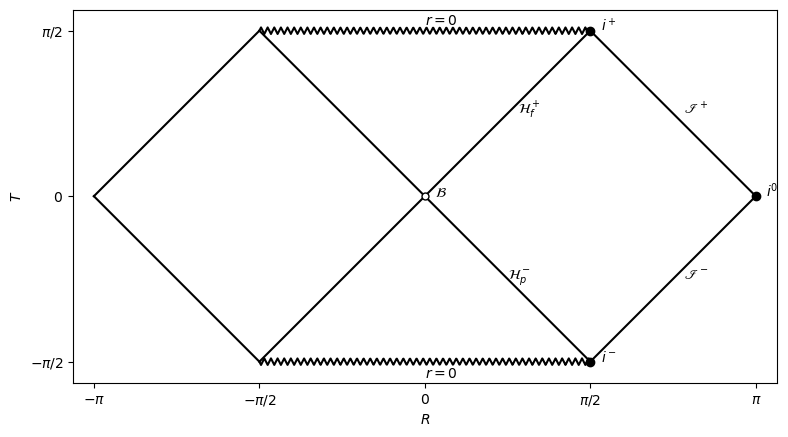

In [12]:
import numpy as np 
import matplotlib.pyplot as plt

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Helvetica"
# })



def schwarzschild_plain():
    # domain
    x = np.linspace(-np.pi/2, np.pi/2, 800)

    k = 50

    width = np.pi
    l = width / k
    amp = l / 2 

    s = (x + np.pi/2) / l
    n = np.floor(s).astype(int)
    n = np.minimum(n, k - 1)     # clamp right endpoint
    f = s - n

    f4 = 4 * f
    segment = np.zeros_like(f)
    mask1 = f4 <= 1
    mask2 = (f4 > 1) & (f4 <= 2)
    mask3 = (f4 > 2) & (f4 <= 3)
    mask4 = f4 > 3
    segment[mask1] = amp*f4[mask1]
    segment[mask2] = amp*(2 - f4[mask2])
    segment[mask3] = -amp*(f4[mask3] - 2)
    segment[mask4] = -amp*(4 - f4[mask4])

    y_zigzag = np.pi/2 + segment

    y_zigzag_neg = -np.pi/2 - segment
    plt.figure(figsize=(8, 8))
    # plotting zigzag lines
    plt.plot(x, y_zigzag, lw=1.5, color='black')
    plt.plot(x, y_zigzag_neg, lw=1.5, color='black')

    # line y = x, x€[-pi/2, pi/2]
    x_line = np.array([-np.pi/2, np.pi/2])
    y_line = x_line
    plt.plot(x_line, y_line, lw=1.5, color='black')

    # line y = -x
    y_line2 = -x_line
    plt.plot(x_line, y_line2, lw=1.5, color='black')

    # Scri+ and Scri-
    x_scri = np.array([np.pi/2, np.pi])
    y_scrip = np.pi - x_scri
    y_scrim = -np.pi + x_scri
    plt.plot(x_scri, y_scrip, lw=1.5, color='black')
    plt.plot(x_scri, y_scrim, lw=1.5, color='black')

    # Scri+ left and Scri- left    
    x_scri_l = np.array([-np.pi, -np.pi/2])
    y_scrip_l = np.pi + x_scri_l
    y_scrim_l = -np.pi - x_scri_l
    plt.plot(x_scri_l, y_scrip_l, lw=1.5, color='black')
    plt.plot(x_scri_l, y_scrim_l, lw=1.5, color='black')




    # Dots for  i-, i0, i+
    plt.plot(np.pi/2, np.pi/2, marker='o', color='black')
    plt.plot(np.pi, 0, marker='o', color='black')
    plt.plot(np.pi/2, -np.pi/2, marker='o', color='black')
    

    # Bifurcation sphere
    plt.plot(0, 0, marker='o', markerfacecolor='white', markeredgecolor='black', markersize=5, linestyle='None')


    # denoting i-, i0, i+
    plt.text(np.pi/2 + 0.1, -np.pi/2, r'$i^-$')
    plt.text(np.pi + 0.1, 0, r'$i^0$')
    plt.text(np.pi/2 + 0.1, np.pi/2, r'$i^+$')
    # denoting r = 0
    plt.text(0, np.pi/2 + 0.06, r'$r = 0$')
    plt.text(0, -np.pi/2 - 0.15, r'$r = 0$')
    # denoting H+-
    plt.text(np.pi/4 + 0.1, np.pi/4, r'$\mathcal{H}^+_f$')
    plt.text(np.pi/4, -np.pi/4, r'$\mathcal{H}^-_p$')
    # denoting scri
    plt.text(3*np.pi/4 + 0.1, np.pi/4, r'$\mathscr{I}^+$')
    plt.text(3*np.pi/4 + 0.1, -np.pi/4, r'$\mathscr{I}^-$')
    # denoting bifurcation sphere
    plt.text(0 + 0.1, 0, r'$\mathcal{B}$')

    # ensure equal scale on both axes
    ax = plt.gca()
    ax.set_aspect('equal', adjustable='box')

    # set ticks to pi
    ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
    tick_labels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']


    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(tick_labels)
    ax.set_yticklabels(tick_labels)

    plt.xlim(-np.pi - 0.2, np.pi + 0.2)
    plt.ylim(-np.pi/2 - 0.2, np.pi/2 + 0.2)
    plt.xlabel(r'$R$')
    plt.ylabel(r'$T$')
    plt.tight_layout()

schwarzschild_plain()





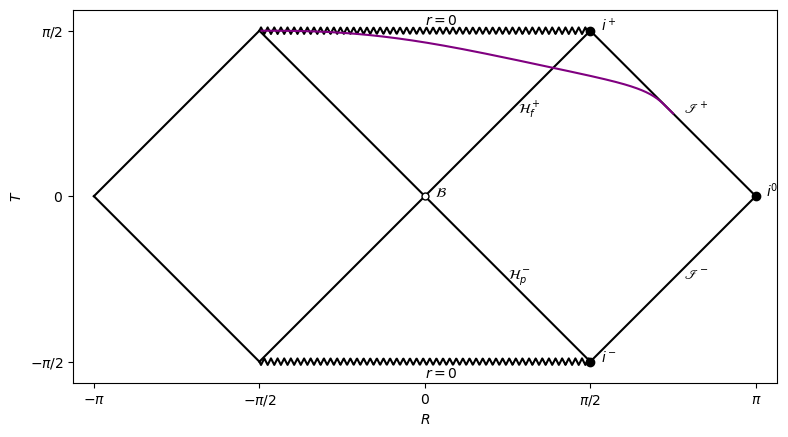

In [ ]:
rh = 2
lamb=rh
def height_hyperbolic(r, rh=rh, lamb=lamb):  # height function for which tau = t + h(r) behaves hyperbolicaly 
    r = np.asarray(r, dtype=float)

    arg1 = np.abs(r/rh - 1)
    arg2 = r/rh

    log1 = np.full_like(r, -np.inf)
    log2 = np.full_like(r, -np.inf)
    thresh = np.exp(np.finfo(float).min)
    mask1 = arg1 > thresh
    mask2 = arg2 > thresh

    log1[mask1] = np.log(arg1[mask1])
    log2[mask2] = np.log(arg2[mask2])

    return (rh*log1 - 2*rh*log2 - r)/lamb

def r_star_of_r(r, rh=rh):
    r = np.asarray(r, dtype=float)

    arg = np.abs(r/rh - 1)
    thresh = np.exp(np.finfo(float).min)
    # thresh = 10**(-2)
    m = arg > thresh
    r_star = np.full_like(r, -np.inf)
    r_star[m] = r[m] + rh*np.log(arg[m])

    
    return r_star


def t_of_tau(tau, r, height_fun, lamb=lamb): # calculates t given a regular time tau obtained by height function
    return lamb*(tau - height_fun(r))


def t_r_star_from_hyperbolic(r, tau, height_fun, lamb=lamb):
    t = lamb*(tau - height_fun(r))
    r_star = r_star_of_r(r)
    return t, r_star

def u_v_nullified(t, r_star):
    u = t - r_star
    v = t + r_star
    return u, v

def U_V_extended(u, v, rh=rh, region="I"):
    """
    Compute extended Kruskal-like coordinates (U, V)
    covering all four regions.

    region = {"I", "II", "III", "IV"}
    """

    # region-dependent signs
    region_signs = {
        "I":   (-1, +1),
        "II":  (+1, +1),
        "III": (+1, -1),
        "IV":  (-1, -1),
    }

    if region not in region_signs:
        raise ValueError("region must be one of 'I', 'II', 'III', 'IV'")

    sU, sV = region_signs[region]

    # exponential arguments (fixed once and for all)
    arg_u = -u / (2 * rh)
    arg_v =  v / (2 * rh)

    # overflow protection
    max_exp = np.log(np.finfo(float).max)
    arg_u = np.clip(arg_u, -max_exp, max_exp)
    arg_v = np.clip(arg_v, -max_exp, max_exp)

    # compute U, V
    U = sU * np.exp(arg_u)
    V = sV * np.exp(arg_v)

    return U, V

def U_V_region_check(tau, r, rh=rh, height=None, lamb=lamb):
    if height == None:
        t = tau
        r_star = r_star_of_r(r, rh=rh)
    else:
        t, r_star = t_r_star_from_hyperbolic(1/sigma, tau, height, rh)
    
    u, v = u_v_nullified(t, r_star)
    
    U = np.empty_like(r)
    V = np.empty_like(r)
    arg_u = u/(2*rh)
    arg_v = v/(2*rh)
    max_exp = np.log(np.finfo(float).max)
    
    # I Region
    r_is_outside_u_is_fin = (r > rh) & (-arg_u < max_exp)
    r_is_outside_u_is_inf = (r > rh) & (-arg_u > max_exp)
    U[r_is_outside_u_is_fin] = -np.exp(-arg_u[r_is_outside_u_is_fin])
    U[r_is_outside_u_is_inf] = -np.inf
    
    r_is_outside_v_is_fin = (r > rh) & (arg_v < max_exp)
    r_is_outside_v_is_inf = (r > rh) & (arg_v > max_exp)
    V[r_is_outside_v_is_fin] = np.exp(arg_v[r_is_outside_v_is_fin])
    V[r_is_outside_v_is_inf] = np.inf

    # II region
    r_is_inside_u_is_fin = (r >= 0) & (r <= rh) & (-arg_u < max_exp) 
    r_is_inside_u_is_inf = (r >= 0) & (r <= rh) & (-arg_u > max_exp)
    U[r_is_inside_u_is_fin] = np.exp(-arg_u[r_is_inside_u_is_fin])
    U[r_is_inside_u_is_inf] = np.inf

    r_is_inside_v_is_fin = (r >= 0) & (r <= rh) & (arg_v < max_exp) 
    r_is_inside_v_is_inf = (r >= 0) & (r <= rh) & (arg_v > max_exp)
    V[r_is_inside_v_is_fin] = np.exp(arg_v[r_is_inside_v_is_fin])
    V[r_is_inside_v_is_inf] = np.inf

# Negative r
    # III region
    n_r_is_outside_u_is_fin = (r < -rh) & (arg_u < max_exp)
    n_r_is_outside_u_is_inf = (r < -rh) & (arg_u > max_exp)
    U[n_r_is_outside_u_is_fin] = np.exp(arg_u[n_r_is_outside_u_is_fin])
    U[n_r_is_outside_u_is_inf] = np.inf

    n_r_is_outside_v_is_fin = (r < -rh) & (-arg_v < max_exp)
    n_r_is_outside_v_is_inf = (r < -rh) & (-arg_v > max_exp)
    V[n_r_is_outside_v_is_fin] = -np.exp(-arg_v[n_r_is_outside_v_is_fin])
    V[n_r_is_outside_v_is_inf] = -np.inf
    
    # IV region
    n_r_is_inside_u_is_fin = (r < 0) & (r > -rh) & (arg_u < max_exp) 
    n_r_is_inside_u_is_inf = (r < 0) & (r > -rh) & (arg_u > max_exp)
    U[n_r_is_inside_u_is_fin] = -np.exp(arg_u[n_r_is_inside_u_is_fin])
    U[n_r_is_inside_u_is_inf] = -np.inf

    n_r_is_inside_v_is_fin = (r < 0) & (r > -rh) & (-arg_v < max_exp) 
    n_r_is_inside_v_is_inf = (r < 0) & (r > -rh) & (-arg_v > max_exp)
    V[n_r_is_inside_v_is_fin] = -np.exp(-arg_v[n_r_is_inside_v_is_fin])
    V[n_r_is_inside_v_is_inf] = -np.inf    
    return U, V


    



def map_to_penrose(u, v):
    
    u_comp = np.arctan(u)

    
    v_comp = np.arctan(v)

    T = u_comp + v_comp
    R = -u_comp + v_comp
    return T, R




sigma_i = 10**(-6)
sigma = np.linspace(sigma_i, 50, 10000)
tau = np.zeros_like(sigma)


U1, V1 = U_V_region_check(tau, 1/sigma, height=height_hyperbolic)

T_outside, R_outside = map_to_penrose(U1, V1)

schwarzschild_plain()
plt.plot(R_outside, T_outside, color='purple')
plt.show()


In [14]:
a = np.array([1, 6, 3, 5])
b = np.array([2, 6, 4, 9])

print((a > 2) & (b > 2))

[False  True  True  True]


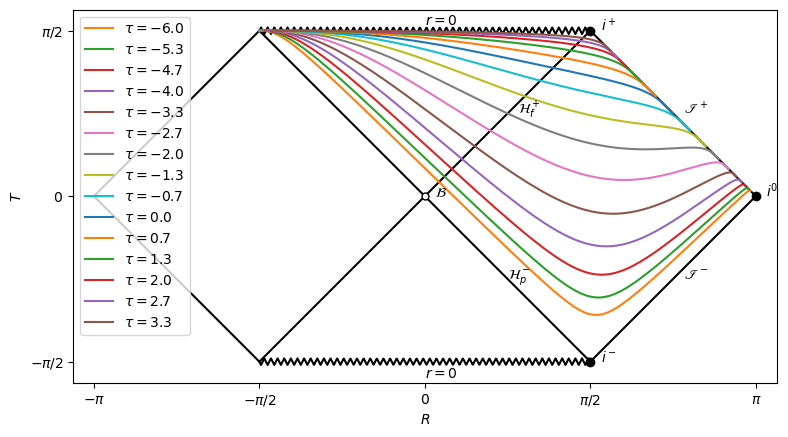

In [15]:
taus_values = np.arange(-6, 4, 2/3)
sigma = np.linspace(sigma_i, 50, 10000)
r = 1/sigma
schwarzschild_plain()
for val in taus_values:
    tau = val*np.ones_like(r)
    U1, V1 = U_V_region_check(tau, r, rh, height=height_hyperbolic)
    T_outside, R_outside = map_to_penrose(U1, V1)
    
    plt.plot(R_outside, T_outside, label=fr'$\tau = {val:.1f}$')
plt.legend()
plt.show()



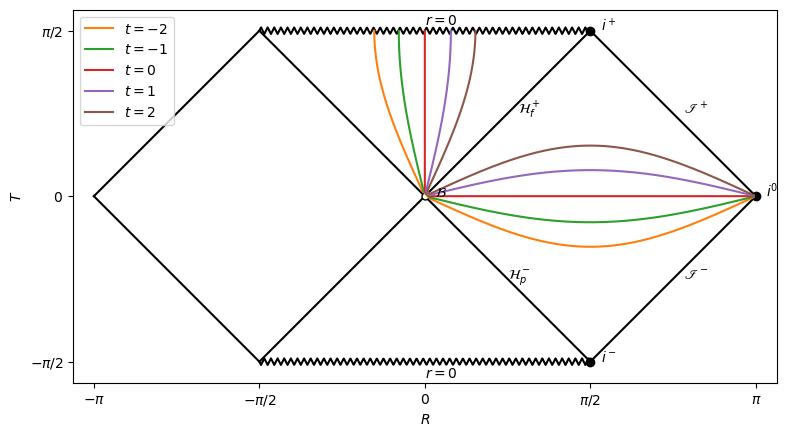

In [16]:
t_vals = np.arange(-2, 3, 1)
r = np.linspace(0, 15, 20000)
schwarzschild_plain()
colors = plt.cm.viridis(np.linspace(0, 1, len(t_vals)))
for i, val in enumerate(t_vals):
    t = val*np.ones_like(r)
    U1, V1 = U_V_region_check(t, r, rh)
    T1, R1 = map_to_penrose(U1, V1)
    plt.plot(R1, T1, label=rf'$t = {val}$')
plt.legend()
plt.show()

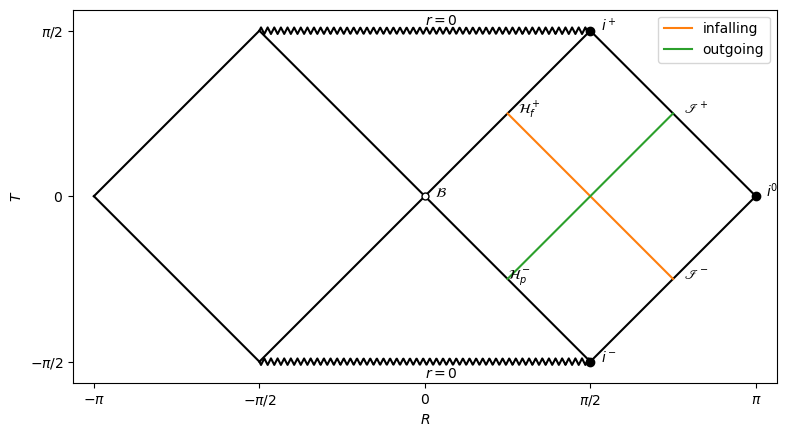

In [17]:
u1 = np.linspace(-100, 100, 1000)
v1 = 0*np.ones_like(u1)
U1, V1 = U_V_extended(u1, v1)

T1, R1 = map_to_penrose(U1, V1)


v2 = np.linspace(-100, 100, 1000)
u2 = 0*np.ones_like(v2)
U2, V2 = U_V_extended(u2, v2)

T2, R2 = map_to_penrose(U2, V2)

schwarzschild_plain()
plt.plot(R1, T1, label='infalling')
plt.plot(R2, T2, label='outgoing')
plt.legend()
plt.show()

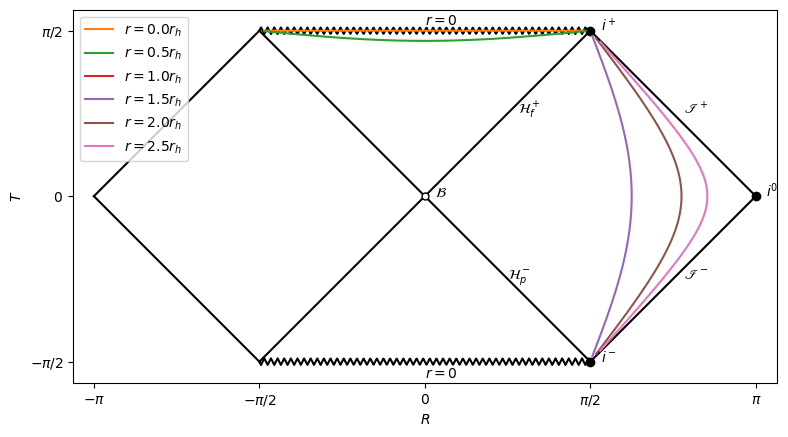

In [18]:
r_vals = np.arange(0, 3, 0.5)*rh
t = np.linspace(-15, 15, 15000)
schwarzschild_plain()
colors = plt.cm.viridis(np.linspace(0, 1, len(r_vals)))
for i, val in enumerate(r_vals):
    r = val*np.ones_like(t)
    U1, V1 = U_V_region_check(t, r, rh)
    T1, R1 = map_to_penrose(U1, V1)
    plt.plot(R1, T1, label=rf'$r = {val/rh:.1f}r_h$')
plt.legend()
plt.show()

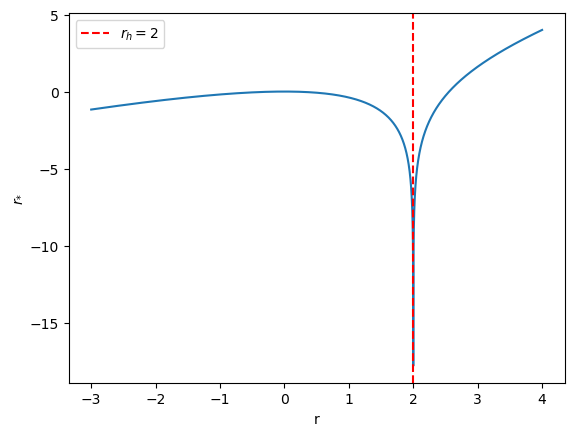

In [19]:
r = np.linspace(-3, 4, 10000)
r_star = r_star_of_r(r, rh=rh)

plt.figure()
plt.plot(r, r_star)
plt.axvline(x=rh, color='red', linestyle='--', label=f'$r_h = {rh}$')
plt.xlabel('r')
plt.ylabel('$r_{{*}}$')
plt.legend()
plt.show()


## Mapping the whole diagram

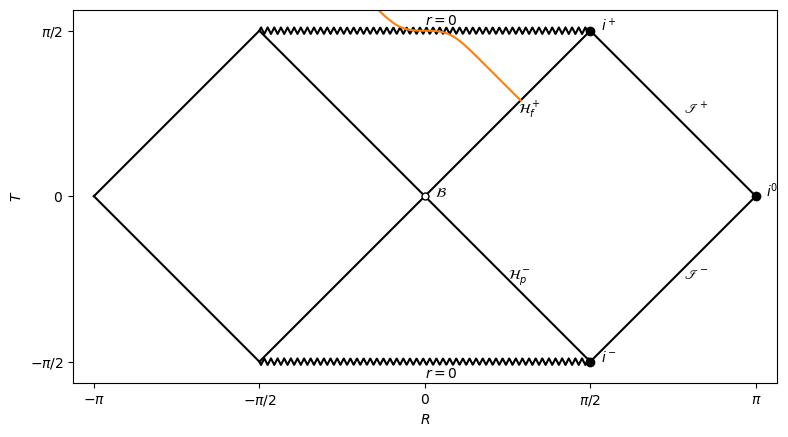

In [22]:
u = np.linspace(-50,50,1001)
v = np.tanh(u)

U, V = U_V_extended(u, v, region="II")
T, R = map_to_penrose(U, V)


schwarzschild_plain()
plt.plot(R, T)



# Class for a convenient future use
### *work in progress*

In [21]:
class Penrose_Diagrams:
    def _schwarzschild_plain(self):
        x = np.linspace(-np.pi/2, np.pi/2, 800)

        k = 50

        width = np.pi
        l = width / k
        amp = l / 2 

        s = (x + np.pi/2) / l
        n = np.floor(s).astype(int)
        n = np.minimum(n, k - 1)     # clamp right endpoint
        f = s - n

        f4 = 4 * f
        segment = np.zeros_like(f)
        mask1 = f4 <= 1
        mask2 = (f4 > 1) & (f4 <= 2)
        mask3 = (f4 > 2) & (f4 <= 3)
        mask4 = f4 > 3
        segment[mask1] = amp*f4[mask1]
        segment[mask2] = amp*(2 - f4[mask2])
        segment[mask3] = -amp*(f4[mask3] - 2)
        segment[mask4] = -amp*(4 - f4[mask4])

        y_zigzag = np.pi/2 + segment

        y_zigzag_neg = -np.pi/2 - segment
        plt.figure(figsize=(8, 8))
        # plotting zigzag lines
        plt.plot(x, y_zigzag, lw=1.5, color='black')
        plt.plot(x, y_zigzag_neg, lw=1.5, color='black')

        # line y = x, x€[-pi/2, pi/2]
        x_line = np.array([-np.pi/2, np.pi/2])
        y_line = x_line
        plt.plot(x_line, y_line, lw=1.5, color='black')

        # line y = -x
        y_line2 = -x_line
        plt.plot(x_line, y_line2, lw=1.5, color='black')

        # Scri+ and Scri-
        x_scri = np.array([np.pi/2, np.pi])
        y_scrip = np.pi - x_scri
        y_scrim = -np.pi + x_scri
        plt.plot(x_scri, y_scrip, lw=1.5, color='black')
        plt.plot(x_scri, y_scrim, lw=1.5, color='black')

        # Scri+ left and Scri- left    
        x_scri_l = np.array([-np.pi, -np.pi/2])
        y_scrip_l = np.pi + x_scri_l
        y_scrim_l = -np.pi - x_scri_l
        plt.plot(x_scri_l, y_scrip_l, lw=1.5, color='black')
        plt.plot(x_scri_l, y_scrim_l, lw=1.5, color='black')




        # Dots for  i-, i0, i+
        plt.plot(np.pi/2, np.pi/2, marker='o', color='black')
        plt.plot(np.pi, 0, marker='o', color='black')
        plt.plot(np.pi/2, -np.pi/2, marker='o', color='black')
        

        # Bifurcation sphere
        plt.plot(0, 0, marker='o', markerfacecolor='white', markeredgecolor='black', markersize=5, linestyle='None')


        # denoting i-, i0, i+
        plt.text(np.pi/2 + 0.1, -np.pi/2, r'$i^-$')
        plt.text(np.pi + 0.1, 0, r'$i^0$')
        plt.text(np.pi/2 + 0.1, np.pi/2, r'$i^+$')
        # denoting r = 0
        plt.text(0, np.pi/2 + 0.06, r'$r = 0$')
        plt.text(0, -np.pi/2 - 0.15, r'$r = 0$')
        # denoting H+-
        plt.text(np.pi/4 + 0.1, np.pi/4, r'$\mathcal{H}^+_f$')
        plt.text(np.pi/4, -np.pi/4, r'$\mathcal{H}^-_p$')
        # denoting scri
        plt.text(3*np.pi/4 + 0.1, np.pi/4, r'$\mathscr{I}^+$')
        plt.text(3*np.pi/4 + 0.1, -np.pi/4, r'$\mathscr{I}^-$')
        # denoting bifurcation sphere
        plt.text(0 + 0.1, 0, r'$\mathcal{B}$')

        # ensure equal scale on both axes
        ax = plt.gca()
        ax.set_aspect('equal', adjustable='box')

        # set ticks to pi
        ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
        tick_labels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']


        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels(tick_labels)
        ax.set_yticklabels(tick_labels)

        plt.xlim(-np.pi - 0.2, np.pi + 0.2)
        plt.ylim(-np.pi/2 - 0.2, np.pi/2 + 0.2)
        plt.xlabel(r'$R$')
        plt.ylabel(r'$T$')
        plt.title('Schwarzschild')
        plt.tight_layout()

    
    def __init__(self, st_type = 'schwarzschild', **kwargs):
        
        self.st_type = st_type # Spacetime type
        self.params = kwargs
        self.height = lambda r: 0  # Setting height function to return always zero
        if self.st_type == 'schwarzschild':
            self._schwarzschild_plain()

    
    def add_trajectory(self, T, R, color=None):
        if color != None:
            plt.plot(T, R, color=color)
        else:
            plt.plot(T, R)
    
    def set_height_function(self, height):
        self.height = height

    def tau_of_t_r(self, t, r):
        return r + self.params['rh']*self.height(r)

    def r_of_tau():
        pass 

    
    